# 02 - RQ1: Can We Predict the Dollar Amount Paid on a Building Claim?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**RQ1:** Can we predict the dollar amount paid on a building claim using flood-zone, construction, policy and geographic features?

This is a **regression** problem: the answer is a number (dollars). We use the clean file from `01_EDA.ipynb`.

**Plan**
1. Prepare the data (paid claims only)
2. Try four models with 5-fold cross validation
3. The harder test: storms the model has never seen
4. What happens if we "cheat" and give the model the damage amount?
5. Which features matter? Can fewer features do the same job?
6. Our answer

## 1. Prepare the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
SEED = 42

df = pd.read_parquet('data/claims_clean.parquet')
print('Claims:', f'{len(df):,}')

# Features: things we know when the claim is reported (no damage, no payment)
NUMBER_FEATURES = ['totalBuildingInsuranceCoverage', 'totalContentsInsuranceCoverage', 'deductible_usd', 'building_age',
                   'numberOfUnits', 'policyCount', 'crsClassCode', 'report_lag_days', 'loss_month', 'named_storm',
                   'elevatedBuildingIndicator', 'postFIRMConstructionIndicator', 'primaryResidenceIndicator', 'rentalPropertyIndicator']
CATEGORY_FEATURES = ['zone', 'foundation', 'occupancy', 'numberOfFloorsInTheInsuredBuilding', 'state_group']

top_states = df['state'].value_counts().head(10).index
df['state_group'] = df['state'].where(df['state'].isin(top_states), 'other')
X_all = pd.get_dummies(df[NUMBER_FEATURES + CATEGORY_FEATURES], columns=CATEGORY_FEATURES, dtype=int)
print('Feature columns after one-hot encoding:', X_all.shape[1])

Claims: 276,570
Feature columns after one-hot encoding: 56


In [2]:
paid = df['amountPaidOnBuildingClaim'] > 0
X = X_all[paid]
y = df.loc[paid, 'amountPaidOnBuildingClaim']
years = df.loc[paid, 'loss_year']
print(f'Paid building claims: {len(y):,}')
print(f'Median payment ${y.median():,.0f}, mean payment ${y.mean():,.0f}')

Paid building claims: 212,932
Median payment $40,318, mean payment $76,471


**How we score the models.** We use **R²**: the share of the differences in payments that the model explains.
1 is perfect, 0 means "no better than always guessing the average", and below 0 means worse than that.
We compute R² on the **dollar amounts**, because the question asks for dollars. We also show the **median error**
(half of the predictions are closer than this).

## 2. Four models with 5-fold cross validation

| Model | Idea |
|---|---|
| Baseline | always predict the median payment |
| Linear regression | a straight-line model. We train it on log(payment) because payments are very skewed, then turn the prediction back into dollars |
| Random forest | many decision trees, each on a random part of the data, and we average them |
| Gradient boosting | trees built one after another, each one fixes the errors of the last one. We use `loss='poisson'`, which works well for money amounts that are always positive |

5-fold cross validation: the claims are cut into 5 parts, every part is the test set once, and we average the 5 scores.
The random forest is slow, so it is trained on a sample of 60,000 claims in each fold.

In [3]:
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import r2_score

def fit_predict(name, X_train, y_train, X_test):
    if name == 'Baseline':
        return np.full(len(X_test), y_train.median())
    if name == 'Linear regression':
        m = LinearRegression().fit(X_train, np.log1p(y_train))
        return np.expm1(np.clip(m.predict(X_test), 0, 17))
    if name == 'Random forest':
        s = X_train.sample(min(60000, len(X_train)), random_state=SEED).index
        m = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(X_train.loc[s], y_train.loc[s])
        return m.predict(X_test)
    m = HistGradientBoostingRegressor(loss='poisson', max_iter=300, learning_rate=0.05, random_state=SEED).fit(X_train, y_train)
    return m.predict(X_test)

MODELS = ['Baseline', 'Linear regression', 'Random forest', 'Gradient boosting']
cv_scores = {m: [] for m in MODELS}
for train_idx, test_idx in KFold(5, shuffle=True, random_state=SEED).split(X):
    Xa, Xb, ya, yb = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
    for m in MODELS:
        cv_scores[m].append(r2_score(yb, fit_predict(m, Xa, ya, Xb)))
cv_table = pd.DataFrame({'mean R2': {m: np.mean(v) for m, v in cv_scores.items()},
                         'std': {m: np.std(v) for m, v in cv_scores.items()},
                         'R2 of each fold': {m: ' '.join(f'{x:.2f}' for x in v) for m, v in cv_scores.items()}})
cv_table.round(3)

,mean R2,std,R2 of each fold
Baseline,-0.057,0.004,-0.05 -0.06 -0.06 -0.06 -0.05
Linear regression,-0.557,0.594,0.04 0.06 -0.68 -0.64 -1.56
Random forest,0.477,0.015,0.48 0.45 0.49 0.48 0.49
Gradient boosting,0.521,0.020,0.53 0.53 0.48 0.54 0.53


**What we see**
- **Gradient boosting is the best model** (R² 0.52), then the random forest (0.48). Both are much better than the baseline (-0.06).
- **Linear regression did not work at all** (mean R² -0.56, and very different between folds). We trained it on log(payment), and when we
  turn the prediction back into dollars, a few predictions become huge. In dollars, these few big mistakes destroy the score.
  We learned that a straight line is not a good model for payments that go from $2 to $10 million.
- The tree models are stable: the five folds give almost the same score.

## 3. The harder test: storms the model has never seen

In cross validation the claims are mixed at random, so claims from the **same hurricane** are in the training part and in the test part.
The model can learn "this storm paid a lot". But for a **future** storm this is not possible.

So we also do a **time split**: train on **2020-2023**, test on **2024-2025** (Helene and Milton).

In [4]:
train, test = years <= 2023, years >= 2024
print(f'Train claims: {train.sum():,}   Test claims: {test.sum():,}')
time_rows = []
preds = {}
for m in MODELS:
    p = fit_predict(m, X[train], y[train], X[test])
    preds[m] = p
    time_rows.append({'model': m, 'R2 (dollars)': r2_score(y[test], p), 'median error $': np.median(np.abs(y[test] - p))})
time_table = pd.DataFrame(time_rows).set_index('model')
time_table['R2 in cross validation'] = cv_table['mean R2']
time_table.round(3)

Train claims: 119,746   Test claims: 93,186


,R2 (dollars),median error $,R2 in cross validation
model,,,
Baseline,-0.175,32290.735,-0.057
Linear regression,-0.183,33517.983,-0.557
Random forest,-0.009,30608.340,0.477
Gradient boosting,0.084,29430.348,0.521


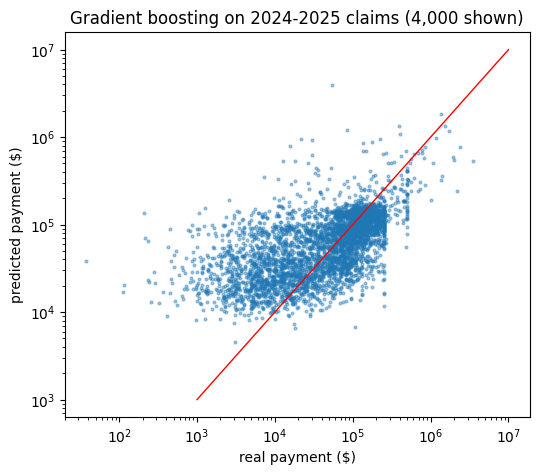

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
s = np.random.default_rng(SEED).choice(test.sum(), 4000, replace=False)
ax.scatter(y[test].values[s], preds['Gradient boosting'][s], s=4, alpha=0.4)
ax.plot([1e3, 1e7], [1e3, 1e7], color='red', lw=1)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('real payment ($)'); ax.set_ylabel('predicted payment ($)')
ax.set_title('Gradient boosting on 2024-2025 claims (4,000 shown)'); plt.show()

**What we see.** This is a big drop. Gradient boosting falls from R² **0.52** in cross validation to only **0.08** on 2024-2025.
The random forest falls to about 0, the same as guessing. The median error of gradient boosting ($29,430) is only a little better than
the baseline ($32,291). The scatter plot shows the same thing: the points are a wide cloud, not a line.

**Why?** In cross validation, claims from Hurricane Ian were in the training part and in the test part, so the model could learn
how much Ian paid. Helene and Milton (2024) were new storms with a different strength and in different places, and nothing in our
features tells the model how strong a new flood will be.

## 4. What if we give the model the damage amount?

`buildingDamageAmount` is measured by the adjuster **after** the flood, so we did not use it (leakage, see notebook 01).
But it is interesting to see how much it would change the score. This shows us **what information is missing** from our features.

In [6]:
X_leak = X.copy()
X_leak['buildingDamageAmount'] = df.loc[paid, 'buildingDamageAmount'].fillna(0).values
p_leak = fit_predict('Gradient boosting', X_leak[train], y[train], X_leak[test])
print(f"Gradient boosting on 2024-2025, our features only         : R2 = {time_table.loc['Gradient boosting', 'R2 (dollars)']:.3f}")
print(f'Gradient boosting on 2024-2025, plus the adjuster damage   : R2 = {r2_score(y[test], p_leak):.3f}')

Gradient boosting on 2024-2025, our features only         : R2 = 0.084
Gradient boosting on 2024-2025, plus the adjuster damage   : R2 = 0.710


**What we see.** With the adjuster's damage figure, R² on 2024-2025 jumps from **0.08** to **0.71**.
So the information that is missing is **how badly the building was damaged**, which depends on how hard the flood hit it.
Our features describe the building and the policy, but they cannot "see" the flood. (We still do not use this model, because the damage
is only known after inspection.)

## 5. Which features matter? Can fewer features do the same job?

We use the random forest's feature importance. Then we explore PCA (5.1), and test the gradient boosting model with only the
top 10 columns and with PCA (keeping 80% of the variance), using the same 5-fold cross validation (5.2).

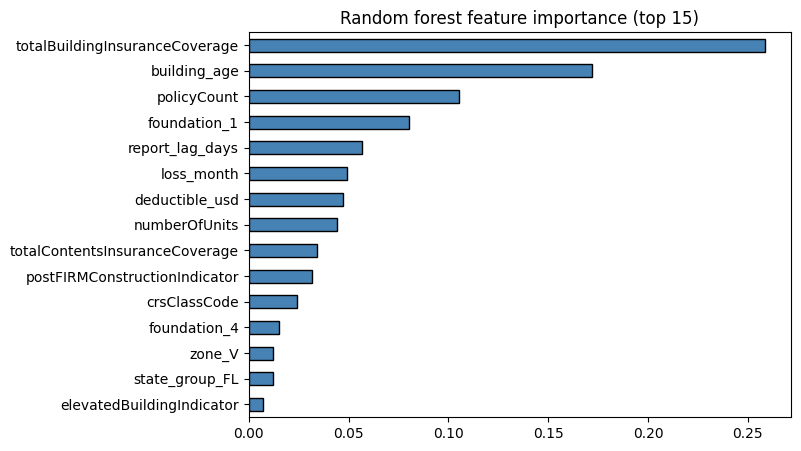

totalBuildingInsuranceCoverage    0.259
building_age                      0.172
policyCount                       0.106
foundation_1                      0.080
report_lag_days                   0.057
loss_month                        0.049
deductible_usd                    0.047
numberOfUnits                     0.044
totalContentsInsuranceCoverage    0.034
postFIRMConstructionIndicator     0.031
dtype: float64

In [7]:
s = X.sample(60000, random_state=SEED).index
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED).fit(X.loc[s], y.loc[s])
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importance.head(15).sort_values().plot.barh(figsize=(7, 5), color='steelblue', edgecolor='black')
plt.title('Random forest feature importance (top 15)'); plt.show()
importance.head(10).round(3)

### 5.1 What is PCA, and how many components do we need?

**PCA (Principal Component Analysis)** makes new columns, called **principal components**, from our 56 columns.
- Each component is a **mix** (weighted sum) of all the original columns.
- The components are made so that the **first one keeps the most variation** in the data, the second one the most of what is left, and so on.
- The components are **not correlated** with each other.

If the first few components keep most of the variation, we can use them **instead of** the 56 columns and the data becomes smaller.

**Before PCA we must standardize** the columns (mean 0, standard deviation 1). Otherwise the coverage column (values up to millions of
dollars) would be the whole first component, only because its numbers are big.

We look at two charts to decide how many components to keep:
- **Elbow (scree) chart:** the variance explained by each component. We look for the point where the line becomes flat (the "elbow").
- **Cumulative sum chart:** the total variance kept by the first *k* components. A common rule is to keep enough components for **80%**.

In this exploration we fit PCA on all paid claims. In the model test (5.2) PCA is fitted again **inside each fold**, on the training part only.

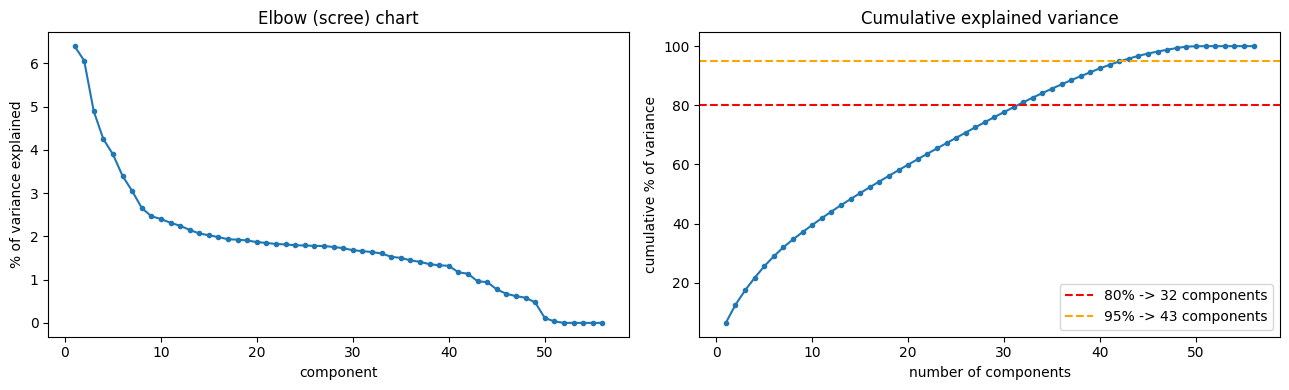

Columns: 56   components for 80%: 32   for 95%: 43


,% variance,cumulative %
PC1,6.4,6.4
PC2,6.1,12.5
PC3,4.9,17.4
PC4,4.3,21.6
PC5,3.9,25.5
PC6,3.4,28.9
PC7,3.1,32.0
PC8,2.7,34.6
PC9,2.5,37.1
PC10,2.4,39.5


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_std = StandardScaler().fit_transform(X)
pca_all = PCA(random_state=SEED).fit(X_std)
explained = pca_all.explained_variance_ratio_
cumulative = np.cumsum(explained)
k80 = int(np.argmax(cumulative >= 0.80) + 1)
k95 = int(np.argmax(cumulative >= 0.95) + 1)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(range(1, len(explained) + 1), explained * 100, marker='o', ms=3)
ax[0].set_xlabel('component'); ax[0].set_ylabel('% of variance explained'); ax[0].set_title('Elbow (scree) chart')
ax[1].plot(range(1, len(cumulative) + 1), cumulative * 100, marker='o', ms=3)
ax[1].axhline(80, color='red', ls='--', label=f'80% -> {k80} components')
ax[1].axhline(95, color='orange', ls='--', label=f'95% -> {k95} components')
ax[1].set_xlabel('number of components'); ax[1].set_ylabel('cumulative % of variance'); ax[1].set_title('Cumulative explained variance')
ax[1].legend(); plt.tight_layout(); plt.show()

print(f'Columns: {X.shape[1]}   components for 80%: {k80}   for 95%: {k95}')
pd.DataFrame({'% variance': explained[:10] * 100, 'cumulative %': cumulative[:10] * 100},
             index=[f'PC{i}' for i in range(1, 11)]).round(1)

**What do the first components mean?** The **loadings** show how much each original column counts in a component.
A big positive or negative loading means the column is important for that component.

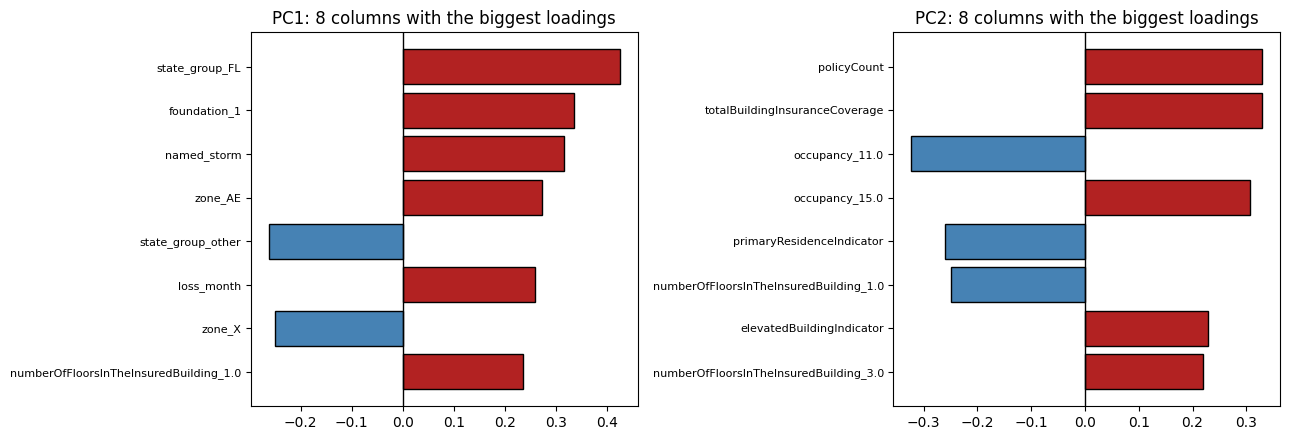

Where is the building coverage (our most important feature)?
   loading on PC1: 0.001   loading on PC2: 0.329


In [9]:
loadings = pd.DataFrame(pca_all.components_[:2].T, index=X.columns, columns=['PC1', 'PC2'])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, pc in zip(ax, ['PC1', 'PC2']):
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(8)
    a.barh(top.index[::-1], top.values[::-1], color=np.where(top.values[::-1] > 0, 'firebrick', 'steelblue'), edgecolor='black')
    a.axvline(0, color='black', lw=1); a.set_title(f'{pc}: 8 columns with the biggest loadings'); a.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()
print('Where is the building coverage (our most important feature)?')
print('   loading on PC1:', round(loadings.loc['totalBuildingInsuranceCoverage', 'PC1'], 3),
      '  loading on PC2:', round(loadings.loc['totalBuildingInsuranceCoverage', 'PC2'], 3))

**What the PCA charts show**
- **There is no clear elbow.** The first component keeps only **6.4%** of the variance, the second 6.1%, and after that the line goes
  down slowly. In a "good" PCA case the first two or three components would keep most of the variance.
- **We need many components:** **32 of 56** for 80% of the variance, and 43 for 95%. So PCA makes the data only a little smaller.
  The reason is that most of our columns are 0/1 columns from one-hot encoding, and they are not strongly correlated with each other.
- **PC1** is mostly "a Florida hurricane claim on a slab house in zone AE": Florida (+0.43), slab foundation (+0.34), named storm (+0.32),
  zone AE (+0.27), and negative for zone X and the other states.
- **PC2** is mostly "a big condo building": policy count (+0.33), building coverage (+0.33) and condo building (+0.31), and negative for
  single-family homes (-0.32) and main homes (-0.26).
- **Our most important feature, the building coverage, has almost no weight in PC1 (0.001)** and is mixed with other columns in PC2.
  This is a first warning: PCA keeps the directions where the columns *vary* most, not the ones that matter most for the *payment*.

### 5.2 Fewer columns in the model: top 10 columns and PCA

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

top10 = list(importance.head(10).index)
small = {'all columns': [], 'top 10 columns': [], 'PCA (80% variance)': []}
n_components = []
for train_idx, test_idx in KFold(5, shuffle=True, random_state=SEED).split(X):
    Xa, Xb, ya, yb = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
    small['all columns'].append(r2_score(yb, fit_predict('Gradient boosting', Xa, ya, Xb)))
    small['top 10 columns'].append(r2_score(yb, fit_predict('Gradient boosting', Xa[top10], ya, Xb[top10])))
    scaler = StandardScaler().fit(Xa)
    pca = PCA(n_components=0.80, random_state=SEED).fit(scaler.transform(Xa))
    n_components.append(pca.n_components_)
    Za, Zb = pca.transform(scaler.transform(Xa)), pca.transform(scaler.transform(Xb))
    small['PCA (80% variance)'].append(r2_score(yb, fit_predict('Gradient boosting', pd.DataFrame(Za), ya, pd.DataFrame(Zb))))
print('PCA components kept:', n_components, 'of', X.shape[1], 'columns')
pd.DataFrame({'columns': [X.shape[1], 10, int(np.mean(n_components))],
              'mean R2 (5-fold)': [np.mean(v) for v in small.values()]}, index=list(small)).round(3)

PCA components kept: [np.int64(32), np.int64(32), np.int64(32), np.int64(32), np.int64(32)] of 56 columns


,columns,mean R2 (5-fold)
all columns,56,0.521
top 10 columns,10,0.456
PCA (80% variance),32,0.417


**What we see**
- The most important feature is the **building coverage** (0.26): a payment can never be more than the insurance bought.
  Then come **building age** (0.17), **policy count** (0.11, big condo buildings have many policies), **slab foundation** and **report delay**.
- **Fewer columns did not help.** With only the top 10 columns R² falls from 0.52 to 0.46.
- **PCA did not help either.** It needed 32 of the 56 columns to keep 80% of the variance, and R² fell to 0.42.
  Most of our columns are 0/1 columns from one-hot encoding, and they are not strongly correlated, so PCA cannot shrink them much.
  PCA also mixes the important coverage column with many weak columns.

## 6. Our answer to RQ1

| Test | Gradient boosting R² (dollars) |
|---|---|
| 5-fold cross validation (storms already in the data) | **0.52** |
| New storms (train 2020-2023, test 2024-2025) | **0.08** |
| New storms, if we "cheat" with the adjuster's damage | 0.71 |

> **Only partly.** For storms that are already in the data, flood-zone, construction, policy and geographic features explain about
> half of the differences in building payments (R² 0.52). For **future** storms they explain almost nothing (R² 0.08).
> The features describe the building, not how hard the flood hit it. When we add the adjuster's damage figure, R² jumps to 0.71,
> so the payment depends mainly on the damage, which these features cannot see.

**What would help:** data about the flood itself, for example rainfall, storm surge height or river levels for each claim.

**What we learned:** a random cross validation can make a model look much better than it is. Testing on later years showed the real picture.